# Optional optimizer benchmark

This notebook reuses the definitions and **same configuration** in
`Scan_Path_Workflow.ipynb`. It shares the generator, model and metric implementations. Run All to generate a fresh equal-budget `history`.
All exposure and motion rules and quality weights come from the main notebook.
Saved JSON and PNG files are not loaded.


In [ ]:
import json
from pathlib import Path
from time import perf_counter
from scipy.optimize import differential_evolution
main_notebook = next((folder/'Scan_Path_Workflow.ipynb'
                      for folder in (Path.cwd(), Path.cwd()/'workflow', *Path.cwd().parents)
                      if (folder/'Scan_Path_Workflow.ipynb').is_file()), None)
if main_notebook is None:
    raise FileNotFoundError('Set main_notebook to Scan_Path_Workflow.ipynb')
shared_cells = json.loads(main_notebook.read_text())['cells']
for cell in shared_cells:
    if cell['cell_type'] == 'code' and set(cell['metadata'].get('tags', [])) & {'definitions', 'configuration', 'setup'}:
        exec(''.join(cell['source']), globals())


## Search settings

Only optimizer settings differ here. Each method gets exactly the same calls per
family/run, with identical allocation to every discrete choice. Grid refinement
runs once; stochastic methods use three seeds. Initial midpoints are shared.
Duplicates count as calls and are reported. Runtime excludes validation and plots.


In [ ]:
EVALUATION_BUDGET = 96
SEEDS = [0, 1, 2]
METHODS = ('grid_refinement', 'random', 'differential_evolution')
if len(SEEDS) < 2 or len(set(SEEDS)) != len(SEEDS):
    raise ValueError('Use at least two distinct stochastic seeds')


In [ ]:
def rank(trial):
    """Feasible first, then loss; violations guide search when infeasible."""
    return (0, trial['loss']) if trial['feasible'] else (1, sum(trial['violations'].values()))


def search(candidate, parameters, method='grid_refinement', budget=96, seed=0):
    """Exactly budget complete workflow calls, including infeasible candidates.

    Every method gets the same allocation for each discrete combination and
    the same initial continuous midpoint. DE polishing and early convergence
    are disabled. Repeated candidates count as evaluations (no hidden cache).
    """
    if method not in ('grid_refinement', 'random', 'differential_evolution'):
        raise ValueError('Unknown search method')
    if not isinstance(budget, int) or isinstance(budget, bool) or budget < 1:
        raise ValueError('budget must be a positive integer')
    discrete = {key: axis for key, axis in parameters.items() if isinstance(axis, list)}
    continuous = {key: axis for key, axis in parameters.items() if isinstance(axis, tuple)}
    combinations = [dict(zip(discrete, point)) for point in product(*discrete.values())]
    minimum = 5 if method == 'differential_evolution' and continuous else 1
    if budget < minimum * len(combinations):
        raise ValueError(f'Budget requires at least {minimum} calls per discrete combination')
    names = list(continuous)
    bounds = np.array(list(continuous.values()), dtype=float).reshape(-1, 2)
    lower, upper = bounds[:, 0], bounds[:, 1]
    midpoint = (lower + upper) / 2
    rng = np.random.default_rng(seed)
    trials = []
    fallback_evaluations = 0
    start = perf_counter()
    for combination_index, discrete in enumerate(combinations):
        allocation = budget // len(combinations) + (combination_index < budget % len(combinations))
        local = []

        def evaluate(vector):
            params = {**discrete, **dict(zip(names, map(float, vector)))}
            trial = candidate(params)
            local.append(trial)
            trials.append(trial)
            return trial

        if not names:
            for _ in range(allocation):
                evaluate([])
        elif method == 'random':
            evaluate(midpoint)
            for _ in range(allocation-1):
                evaluate(rng.uniform(lower, upper))
        elif method == 'grid_refinement':
            evaluate(midpoint)
            coarse = list(product(*[np.linspace(lo, hi, 3) for lo, hi in bounds]))
            remaining_coarse = min(len(coarse), max(0, allocation//2 - 1))
            used = {tuple(midpoint)}
            if remaining_coarse:
                for index in np.linspace(0, len(coarse)-1, remaining_coarse, dtype=int):
                    vector = np.asarray(coarse[index])
                    if tuple(vector) not in used:
                        evaluate(vector)
                        used.add(tuple(vector))
            step = (upper-lower) / 4
            while len(local) < allocation:
                incumbent = min(local, key=rank)
                center = np.array([incumbent['params'][name] for name in names])
                before = len(local)
                for axis in range(len(names)):
                    for direction in (-1, 1):
                        vector = center.copy()
                        vector[axis] = np.clip(vector[axis] + direction*step[axis], lower[axis], upper[axis])
                        if tuple(vector) not in used and len(local) < allocation:
                            evaluate(vector)
                            used.add(tuple(vector))
                step /= 2
                if len(local) == before:
                    # Deterministic fallback for numerical stagnation at bounds.
                    index = len(local)+1
                    unit = np.mod(index * np.sqrt(np.arange(2, len(names)+2)), 1)
                    evaluate(lower + unit * (upper-lower))
        else:
            class BudgetReached(Exception):
                pass

            def objective(vector):
                if len(local) == allocation:
                    raise BudgetReached
                trial = evaluate(vector)
                if trial['feasible']:
                    return .5 + np.arctan(trial['loss'])/np.pi
                return 2. + sum(trial['violations'].values())

            population = rng.uniform(lower, upper, size=(5, len(names)))
            population[0] = midpoint
            try:
                differential_evolution(objective, bounds, init=population, seed=rng,
                                       maxiter=allocation, tol=0, atol=0, polish=False,
                                       updating='immediate', workers=1)
            except BudgetReached:
                pass
            # If a constant objective terminated DE, spend remaining calls on
            # random exploration, counted and disclosed in the same history.
            while len(local) < allocation:
                objective(rng.uniform(lower, upper))
                fallback_evaluations += 1
    seconds = perf_counter() - start
    unique = len({tuple(sorted(trial['params'].items())) for trial in trials})
    return {'method': method, 'seed': None if method == 'grid_refinement' else seed,
            'records': trials, 'best': best_trial(trials), 'seconds': seconds,
            'evaluations': len(trials), 'unique_candidates': unique,
            'fallback_evaluations': fallback_evaluations}


## Run comparisons and validate winners

Discrete choices are enumerated. Grid refinement samples a coarse continuous grid
and shrinks coordinate neighborhoods. DE uses a five-member population per tuple,
with no polishing; early constant-objective convergence uses disclosed random
fallback. Every run keeps exactly the requested calls, including infeasible points.
Winners are validated using the same waveform, schedule and finer spatial queries.
The history stores scalar records to limit memory; diagnostic replay calls are
outside search budgets. Failures remain visible rather than becoming winners.


In [ ]:
history, runs = [], []
for name, parameters in parameter_spaces.items():
    def candidate(params, name=name):
        result = evaluate(params, **components[name])
        return {key: value for key, value in result.items() if key not in ('commanded', 'realized')}
    history.append({**candidate({}), 'family': name, 'role': 'baseline', 'method': 'baseline', 'seed': None})
    for method in METHODS:
        for seed in ([0] if method == 'grid_refinement' else SEEDS):
            run = search(candidate, parameters, method, EVALUATION_BUDGET, seed)
            run['family'] = name
            assert run['evaluations'] == EVALUATION_BUDGET
            history.extend({**record, 'family': name, 'role': 'search', 'method': method, 'seed': run['seed']}
                           for record in run['records'])
            run.pop('records')
            winner = run['best']
            run['validated'] = None
            if winner:
                original = evaluate(winner['params'], **components[name])
                fine = evaluate(winner['params'], **{**components[name], 'generator': lambda _: original['commanded'],
                    'instrument': replace(model, substeps=8),
                    'metrics': tuple(replace(metric, query_bins=192) if isinstance(metric, Coverage) else metric
                                     for metric in metric_functions)})
                a, b = original['realized'].trajectory, fine['realized'].trajectory
                assert np.array_equal(a.t[a.acquire], b.t[b.acquire])
                assert np.array_equal(a.exposure[a.acquire], b.exposure[b.acquire])
                run['validated'] = {key: value for key, value in fine.items() if key not in ('commanded', 'realized')}
            runs.append(run)
            best_text = 'none' if winner is None else f"{winner['loss']:.4f}"
            print(f"{name:18s} {method:23s} seed={str(run['seed']):4s} "
                  f"calls={run['evaluations']} time={run['seconds']:.3f}s best={best_text}")


straight_strokes   grid_refinement         seed=None calls=96 time=1.144s best=1.4665
straight_strokes   random                  seed=0    calls=96 time=1.204s best=1.4730
straight_strokes   random                  seed=1    calls=96 time=1.240s best=1.4888
straight_strokes   random                  seed=2    calls=96 time=1.202s best=1.4863
straight_strokes   differential_evolution  seed=0    calls=96 time=1.245s best=1.4793
straight_strokes   differential_evolution  seed=1    calls=96 time=0.850s best=1.4839
straight_strokes   differential_evolution  seed=2    calls=96 time=0.589s best=1.4803
raster             grid_refinement         seed=None calls=96 time=0.537s best=1.6873
raster             random                  seed=0    calls=96 time=0.536s best=1.6890
raster             random                  seed=1    calls=96 time=0.534s best=1.6885
raster             random                  seed=2    calls=96 time=0.544s best=1.6886
raster             differential_evolution  seed=0    c

## Optimization history and Pareto tradeoffs

These plots use the current benchmark history.


249 nondominated candidates among 4774 feasible search records


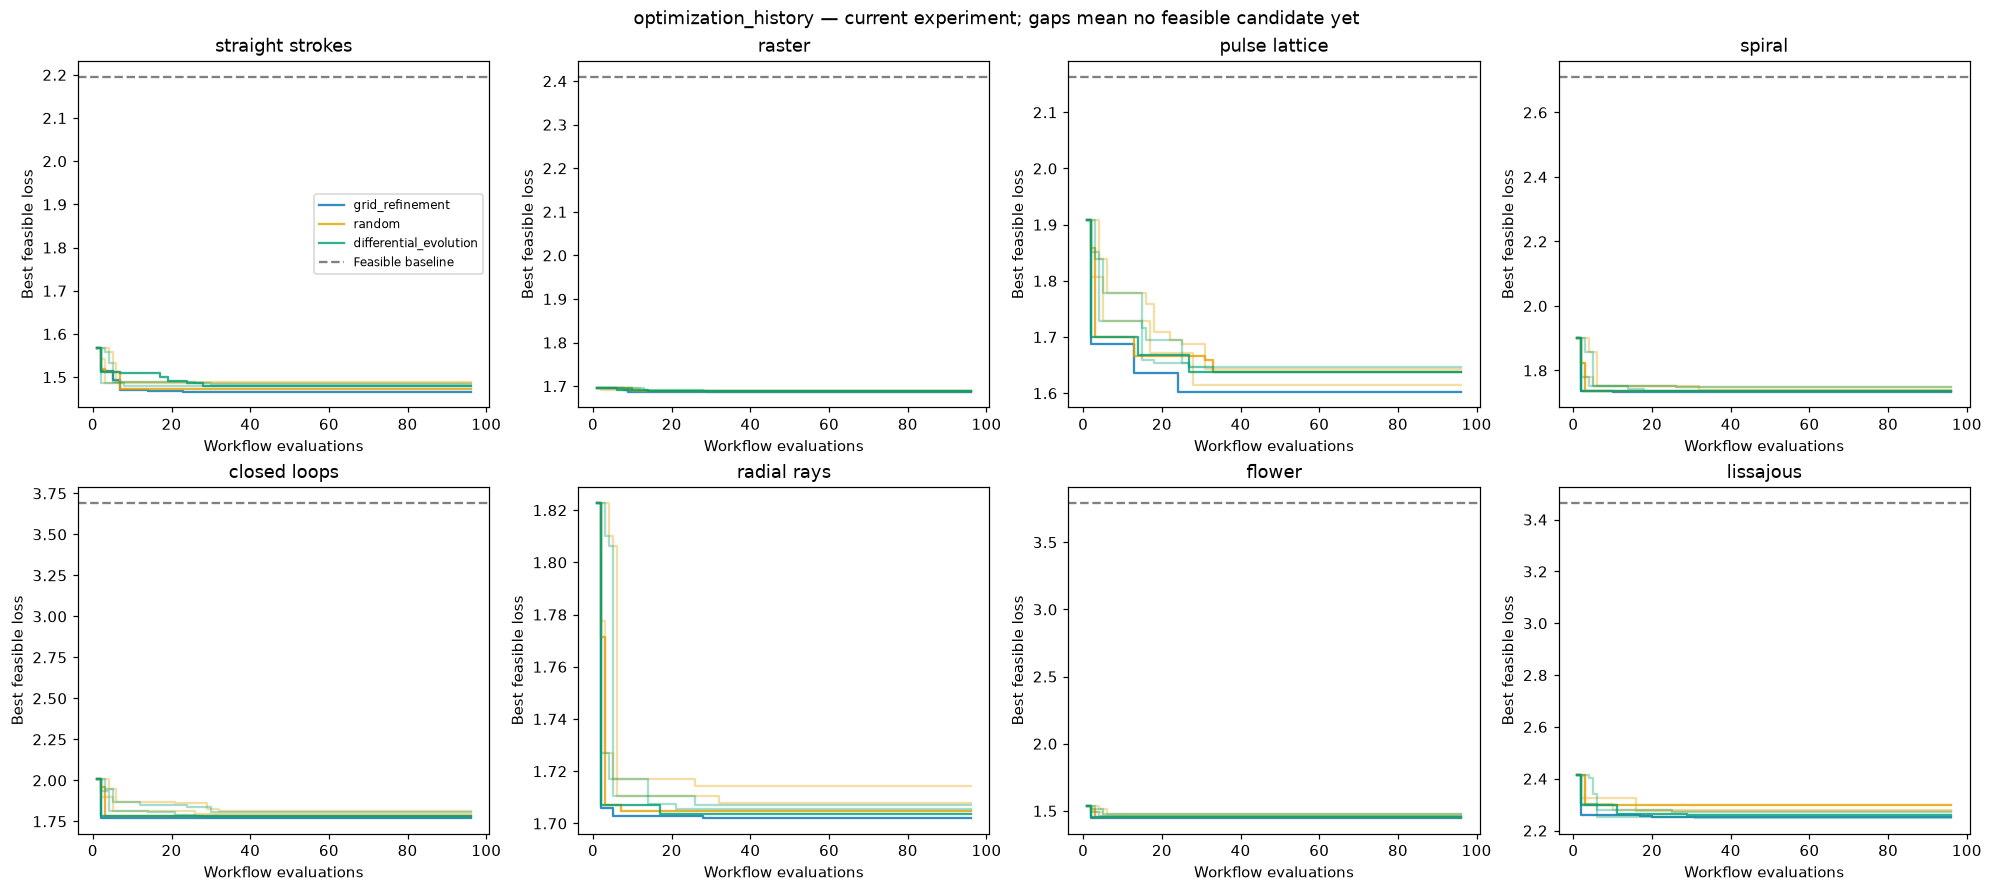

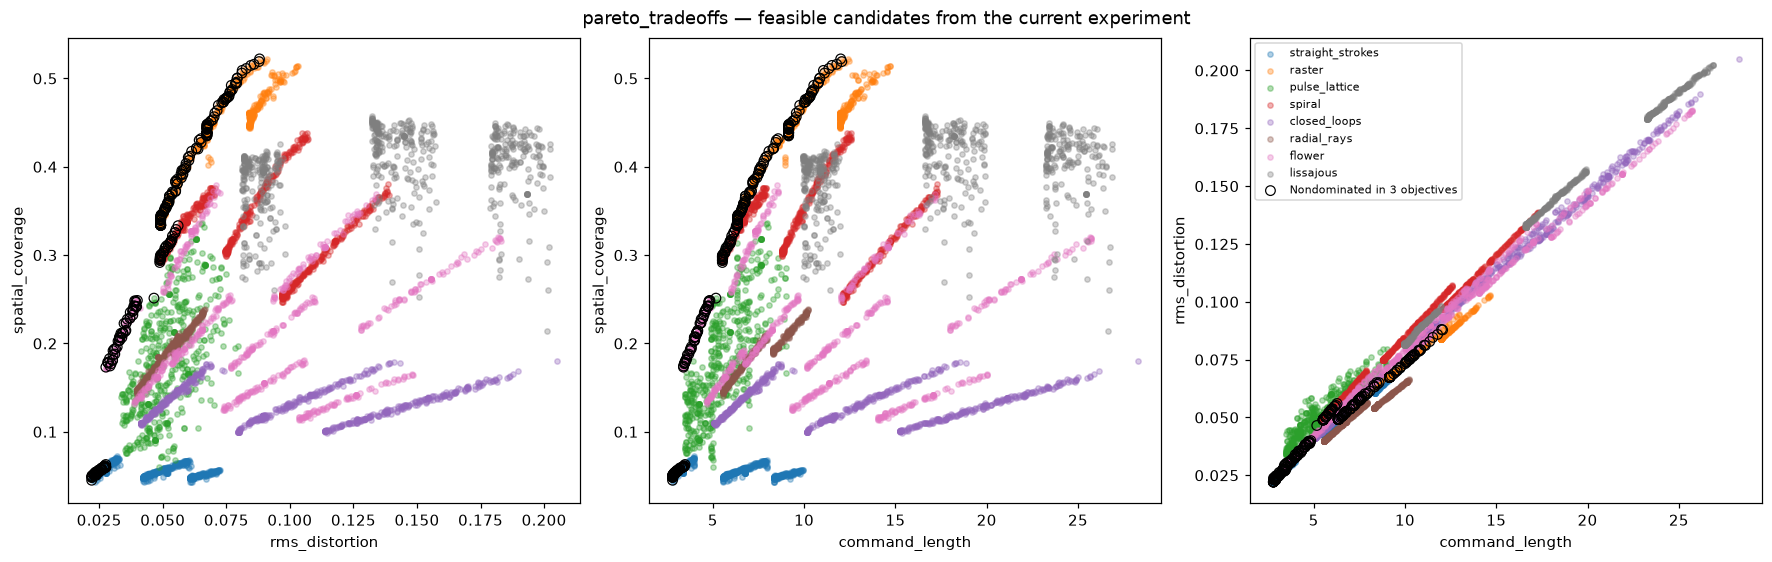

In [ ]:
family_names = list(dict.fromkeys(record['family'] for record in history))
columns = min(4, len(family_names))
rows = (len(family_names)+columns-1)//columns
fig, axes = plt.subplots(rows, columns, figsize=(columns*4.5, rows*4), squeeze=False, constrained_layout=True)
colors = {'grid': '#0072B2', 'grid_refinement': '#0072B2', 'random': '#E69F00', 'differential_evolution': '#009E73'}
for ax in list(axes.flat)[len(family_names):]:
    ax.set_visible(False)
for ax, name in zip(axes.flat, family_names):
    records = [record for record in history if record['family'] == name and record['role'] == 'search']
    plot_runs = list(dict.fromkeys((record['method'], record['seed']) for record in records))
    for method, seed in plot_runs:
        run = [record for record in records if (record['method'], record['seed']) == (method, seed)]
        losses = np.array([record['loss'] if record['feasible'] else np.inf for record in run])
        incumbent = np.minimum.accumulate(losses)
        incumbent[~np.isfinite(incumbent)] = np.nan
        first_seed = seed == next(s for m, s in plot_runs if m == method)
        ax.step(np.arange(1, len(run)+1), incumbent, where='post', color=colors[method],
                alpha=.8 if first_seed else .35, label=method if first_seed else None)
    baseline = next(record for record in history if record['family'] == name and record['role'] == 'baseline')
    if baseline['feasible']:
        ax.axhline(baseline['loss'], color='gray', ls='--', label='Feasible baseline')
    ax.set(title=name.replace('_', ' '), xlabel='Workflow evaluations', ylabel='Best feasible loss')
axes.flat[0].legend(fontsize=8)
fig.suptitle('optimization_history — current experiment; gaps mean no feasible candidate yet')
plt.show()

search_records = [record for record in history if record['role'] == 'search']
feasible = [record for record in search_records if record['feasible']]
values = np.array([[-r['metrics']['spatial_coverage'], r['metrics']['rms_distortion'],
                    r['metrics']['command_length']] for r in feasible]).reshape(-1, 3)
front = [i for i, value in enumerate(values)
         if not np.any(np.all(values <= value, axis=1) & np.any(values < value, axis=1))]
fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
pairs = [('rms_distortion', 'spatial_coverage'), ('command_length', 'spatial_coverage'),
         ('command_length', 'rms_distortion')]
palette = plt.get_cmap('tab10')
for ax, (xmetric, ymetric) in zip(axes, pairs):
    for family_index, name in enumerate(family_names):
        points = [record for record in feasible if record['family'] == name]
        ax.scatter([r['metrics'][xmetric] for r in points], [r['metrics'][ymetric] for r in points],
                   s=12, alpha=.35, color=palette(family_index), label=name)
    points = [feasible[i] for i in front]
    ax.scatter([r['metrics'][xmetric] for r in points], [r['metrics'][ymetric] for r in points],
               s=40, facecolors='none', edgecolors='black', lw=.8, label='Nondominated in 3 objectives')
    ax.set(xlabel=xmetric, ylabel=ymetric)
axes[-1].legend(fontsize=7)
fig.suptitle('pareto_tradeoffs — feasible candidates from the current experiment')
plt.show()
print(len(front), 'nondominated candidates among', len(feasible), 'feasible search records')


## Method comparison

Compare median validated loss, wall time and feasibility. Whiskers show the
observed seed range, not confidence intervals. One deterministic grid/refinement
run has no seed variability. Missing loss bars indicate no validated winner.
These results describe only this configuration and evaluation budget.


Total search calls: 5376
DE random fallback calls: 2


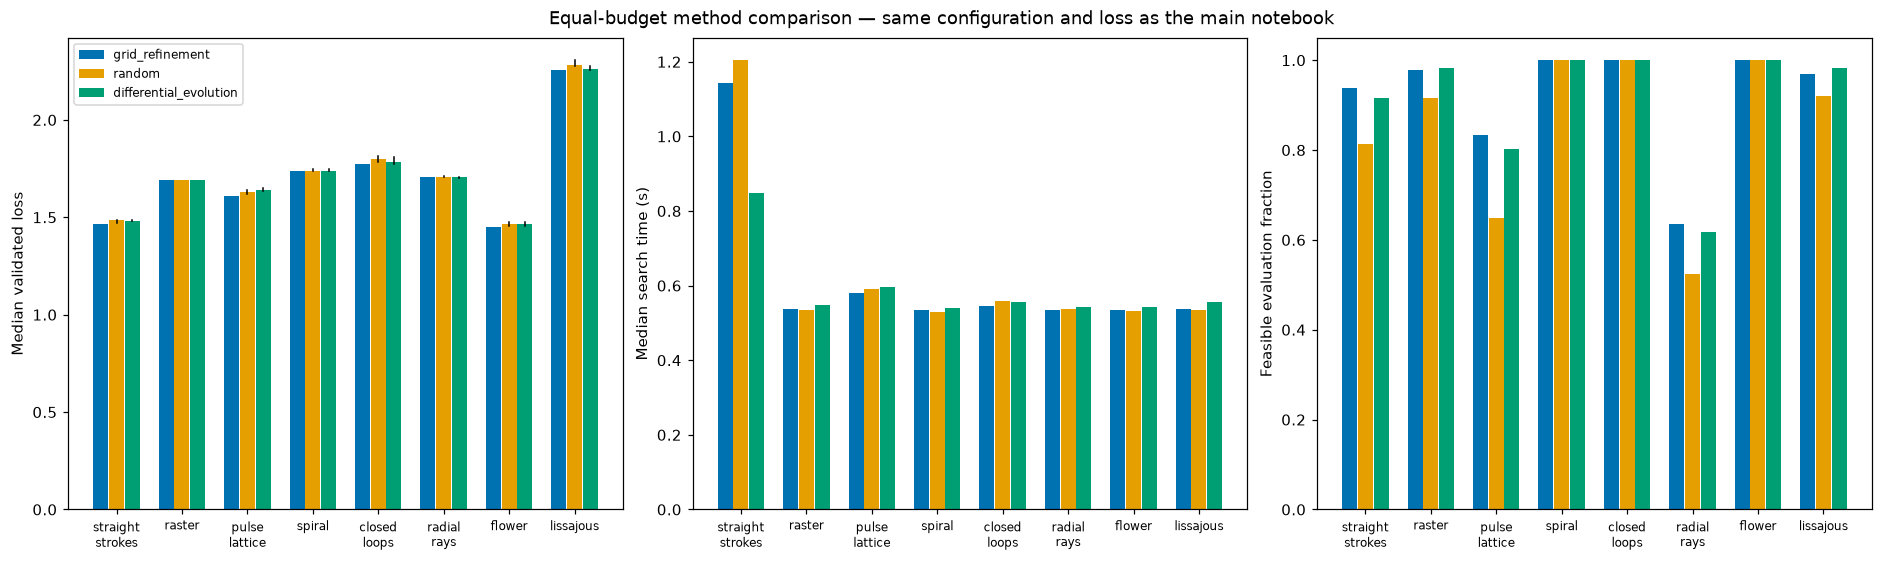

In [ ]:
family_names = list(parameter_spaces)
x = np.arange(len(family_names))
fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
for method_index, method in enumerate(METHODS):
    position = x+(method_index-1)*.24
    for i, name in enumerate(family_names):
        group = [run for run in runs if run['family'] == name and run['method'] == method]
        losses = [run['validated']['loss'] for run in group if run['validated'] and run['validated']['feasible']]
        if losses:
            axes[0].bar(position[i], np.median(losses), .23, color=colors[method], label=method if i == 0 else None)
            axes[0].plot([position[i]]*2, [min(losses), max(losses)], color='black', lw=1)
        axes[1].bar(position[i], np.median([run['seconds'] for run in group]), .23, color=colors[method])
        count = sum(record['feasible'] for record in history if record['family'] == name
                    and record['role'] == 'search' and record['method'] == method)
        axes[2].bar(position[i], count/(len(group)*EVALUATION_BUDGET), .23, color=colors[method])
for ax, label in zip(axes, ['Median validated loss', 'Median search time (s)', 'Feasible evaluation fraction']):
    ax.set_xticks(x, [name.replace('_', '\n') for name in family_names], fontsize=8)
    ax.set(ylabel=label)
axes[0].legend(fontsize=8)
fig.suptitle('Equal-budget method comparison — same configuration and loss as the main notebook')
plt.show()
print('Total search calls:', sum(run['evaluations'] for run in runs))
print('DE random fallback calls:', sum(run['fallback_evaluations'] for run in runs))


## Contract checks

These checks exercise exposure fairness, analytic instrument response and feasibility
selection. Add extra diagnostics only when they answer a scientific question.


In [ ]:
assert all(r['metrics']['acquisition_count'] == config['acquisitions'] for r in history)
assert all(abs(r['metrics']['total_exposure']-config['exposure']) < 1e-12 for r in history)
assert best_trial([{'feasible': False, 'loss': -1e9}]) is None
for name, generator in generators.items():
    if name == 'pulse_lattice':
        raw = generator({})
        budgeted = components[name]['generator']({})
        assert np.all(raw.acquire[budgeted.acquire])
t = np.array([0., .03, .2, .8, 1.])
ramp = Trajectory(np.column_stack((t, np.zeros_like(t))), t)
actual = LagInstrument(tau=.1, drift=(0, 0))(ramp).trajectory.xy[:, 0]
np.testing.assert_allclose(actual, t-.1*(1-np.exp(-t/.1)), atol=1e-13)
print('Exposure, blanking, feasibility and analytic response checks passed.')
